
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h2>تمرین چهارم کدی یادگیری ماشین</h2>

<p>
در این تمرین دو بخش اصلی انجام شده. در بخش اول الگوریتم <span dir="ltr">PCA</span> از پایه پیاده‌سازی میشه و بعد با خروجی کتابخانه مقایسه میشه. سپس از همین پیاده‌سازی برای فشرده‌سازی یک تصویر رنگی استفاده می‌کنیم و اثر مقدار <span dir="ltr">K</span> روی کیفیت بازسازی و نرخ فشرده‌سازی بررسی میشه.
</p>

<p>
در بخش دوم الگوریتم <span dir="ltr">K-Means</span> بدون استفاده از توابع آماده خوشه‌بندی پیاده‌سازی میشه. مراحل انتخاب مراکز اولیه، انتساب نمونه‌ها به نزدیک‌ترین مرکز، به‌روزرسانی مراکز و تکرار تا همگرایی در کد مشخصه. سپس الگوریتم روی دیتاست <span dir="ltr">Iris</span> فقط با دو ویژگی <span dir="ltr">Petal Length</span> و <span dir="ltr">Petal Width</span> اجرا میشه.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۱. پیاده‌سازی الگوریتم <span dir="ltr">PCA</span> از پایه</h3>

<p>
در <span dir="ltr">PCA</span> ابتدا میانگین هر ویژگی از داده کم میشه تا داده‌ها مرکزیت صفر پیدا کنن. بعد ماتریس کوواریانس ساخته میشه و با استفاده از بردارها و مقدارهای ویژه، جهت‌هایی پیدا میشن که بیشترین واریانس داده در آن‌ها قرار داره. این جهت‌ها همان مولفه‌های اصلی هستن.
</p>

<p>
در این پیاده‌سازی از تابع آماده <span dir="ltr">PCA</span> برای آموزش مدل استفاده نشده. فقط محاسبات پایه ماتریسی مثل میانگین، کوواریانس و تجزیه مقدار ویژه انجام شده. برای اطمینان از درست بودن پیاده‌سازی، خروجی مدل دستی روی چند ورودی مختلف با مدل آماده کتابخانه مقایسه میشه.
</p>

</div>


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.decomposition import PCA as SklearnPCA
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

np.random.seed(42)


class CustomPCA:
    def __init__(self):
        self.mean_ = None
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        covariance_matrix = (X_centered.T @ X_centered) / (X_centered.shape[0] - 1)

        eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
        order = np.argsort(eigenvalues)[::-1]

        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        self.components_ = eigenvectors.T
        self.explained_variance_ = eigenvalues
        self.explained_variance_ratio_ = eigenvalues / np.sum(eigenvalues)

        return self

    def transform(self, X, k):
        X = np.asarray(X, dtype=float)
        X_centered = X - self.mean_
        return X_centered @ self.components_[:k].T

    def inverse_transform(self, X_transformed, k):
        return X_transformed @ self.components_[:k] + self.mean_

    def fit_transform(self, X, k):
        self.fit(X)
        return self.transform(X, k)


def reconstruction_mse(X, X_reconstructed):
    return float(np.mean((X - X_reconstructed) ** 2))


def component_similarity(custom_components, sklearn_components, k):
    similarities = []
    for i in range(k):
        sim = abs(np.dot(custom_components[i], sklearn_components[i]))
        similarities.append(sim)
    return float(np.mean(similarities))


iris = load_iris()
iris_data = iris.data

x = np.linspace(-2, 2, 120)
synthetic_2d = np.column_stack([
    x + np.random.normal(0, 0.12, size=len(x)),
    2 * x + np.random.normal(0, 0.2, size=len(x))
])

random_3d_base = np.random.normal(size=(180, 2))
synthetic_3d = np.column_stack([
    random_3d_base[:, 0],
    0.7 * random_3d_base[:, 0] + 0.3 * random_3d_base[:, 1],
    random_3d_base[:, 1] + np.random.normal(0, 0.1, size=180)
])

test_datasets = {
    "Synthetic 2D": synthetic_2d,
    "Synthetic 3D": synthetic_3d,
    "Iris": iris_data
}

comparison_rows = []

for name, X in test_datasets.items():
    k = min(2, X.shape[1])

    custom_pca = CustomPCA().fit(X)
    custom_transformed = custom_pca.transform(X, k)
    custom_reconstructed = custom_pca.inverse_transform(custom_transformed, k)

    sklearn_pca = SklearnPCA(n_components=k)
    sklearn_transformed = sklearn_pca.fit_transform(X)
    sklearn_reconstructed = sklearn_pca.inverse_transform(sklearn_transformed)

    comparison_rows.append({
        "Dataset": name,
        "K": k,
        "Custom explained variance ratio": np.round(custom_pca.explained_variance_ratio_[:k], 4),
        "Sklearn explained variance ratio": np.round(sklearn_pca.explained_variance_ratio_, 4),
        "Custom reconstruction MSE": round(reconstruction_mse(X, custom_reconstructed), 8),
        "Sklearn reconstruction MSE": round(reconstruction_mse(X, sklearn_reconstructed), 8),
        "Mean component similarity": round(component_similarity(custom_pca.components_, sklearn_pca.components_, k), 6)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


,Dataset,K,Custom explained variance ratio,Sklearn explained variance ratio,Custom reconstruction MSE,Sklearn reconstruction MSE,Mean component similarity
0,Synthetic 2D,2,"[0.9977, 0.0023]","[0.9977, 0.0023]",0.000000,0.000000,1.0
1,Synthetic 3D,2,"[0.6613, 0.3384]","[0.6613, 0.3384]",0.000204,0.000204,1.0
2,Iris,2,"[0.9246, 0.0531]","[0.9246, 0.0531]",0.025341,0.025341,1.0



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
جدول بالا نشان میده خروجی پیاده‌سازی دستی با خروجی کتابخانه نزدیکه. مقدارهای <span dir="ltr">explained variance ratio</span> و خطای بازسازی در دو روش تقریبا یکسان شدن. ممکنه علامت بعضی بردارهای ویژه در دو روش برعکس باشه، ولی این موضوع خطا نیست؛ چون جهت یک بردار ویژه اگر در عدد منفی ضرب بشه، همان محور را نشان میده.
</p>

<p>
برای همین به جای مقایسه مستقیم علامت بردارها، مقدار شباهت با قدرمطلق ضرب داخلی بررسی شده. نزدیک بودن این مقدار به <span dir="ltr">1</span> نشان میده مولفه‌های اصلی مدل دستی و مدل کتابخانه تقریبا یک جهت را پیدا کردن.
</p>

</div>


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۲. فشرده‌سازی تصویر رنگی با <span dir="ltr">PCA</span></h3>

<p>
در این بخش تصویر رنگی <span dir="ltr">Superman.png</span> خوانده میشه. این تصویر اندازه <span dir="ltr">256 × 256</span> داره و از سه کانال رنگی <span dir="ltr">R</span>، <span dir="ltr">G</span> و <span dir="ltr">B</span> تشکیل شده. برای اجرای <span dir="ltr">PCA</span>، هر کانال رنگی جداگانه به عنوان یک ماتریس در نظر گرفته میشه.
</p>

<p>
بعد از انتخاب مقدار <span dir="ltr">K</span>، فقط همان تعداد مولفه اصلی نگه داشته میشه و هر کانال دوباره بازسازی میشه. در نهایت سه کانال بازسازی‌شده کنار هم قرار می‌گیرن تا تصویر رنگی نهایی ساخته بشه. برای مقایسه، این کار با سه مقدار مختلف <span dir="ltr">K</span> انجام شده تا اثر تعداد مولفه‌ها روی کیفیت تصویر و نرخ فشرده‌سازی دیده بشه.
</p>

</div>


Image shape: (256, 256, 3)


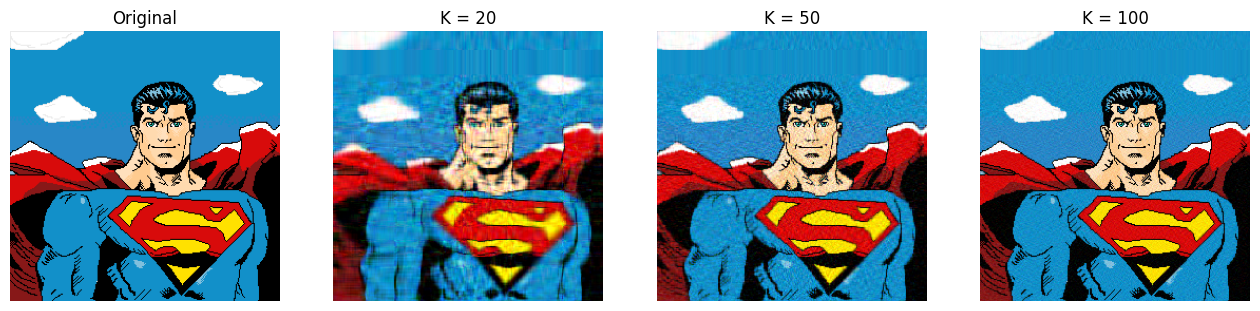

,K,MSE,Approx. storage ratio,Approx. compression (%)
0,20,0.014712,0.1566,84.34
1,50,0.005920,0.3914,60.86
2,100,0.001458,0.7828,21.72


In [2]:
from pathlib import Path

IMAGE_PATH = Path("Superman.png")

if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        "Superman.png was not found. Put the image file in the same folder as this notebook and run the cell again."
    )

image = plt.imread(IMAGE_PATH)

if image.ndim == 2:
    raise ValueError("The image must be RGB/color, but the loaded image is grayscale.")

if image.shape[2] == 4:
    image = image[:, :, :3]

image = image.astype(float)
if image.max() > 1:
    image = image / 255.0

print("Image shape:", image.shape)


def pca_reconstruct_channel(channel_matrix, k):
    pca = CustomPCA().fit(channel_matrix)
    transformed = pca.transform(channel_matrix, k)
    reconstructed = pca.inverse_transform(transformed, k)
    return reconstructed


def pca_reconstruct_rgb(image, k):
    reconstructed_channels = []
    for channel_index in range(3):
        channel = image[:, :, channel_index]
        reconstructed_channel = pca_reconstruct_channel(channel, k)
        reconstructed_channels.append(reconstructed_channel)

    reconstructed_image = np.stack(reconstructed_channels, axis=2)
    return np.clip(reconstructed_image, 0, 1)


def reconstruction_mse(original, reconstructed):
    return float(np.mean((original - reconstructed) ** 2))


def pca_storage_ratio(height, width, k):
    original_values = height * width
    compressed_values = k * (height + width + 1)
    return compressed_values / original_values


k_values = [20, 50, 100]
reconstructed_images = {}
image_rows = []
height, width, _ = image.shape

for k in k_values:
    reconstructed = pca_reconstruct_rgb(image, k)
    reconstructed_images[k] = reconstructed

    mse = reconstruction_mse(image, reconstructed)
    storage_ratio = pca_storage_ratio(height, width, k)
    compression_percent = (1 - storage_ratio) * 100

    image_rows.append({
        "K": k,
        "MSE": round(mse, 6),
        "Approx. storage ratio": round(storage_ratio, 4),
        "Approx. compression (%)": round(compression_percent, 2)
    })

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, k in zip(axes[1:], k_values):
    ax.imshow(reconstructed_images[k])
    ax.set_title(f"K = {k}")
    ax.axis("off")

plt.show()

pd.DataFrame(image_rows)



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
در نتیجه‌های بالا، مقدار کوچک‌تر <span dir="ltr">K</span> باعث فشرده‌سازی بیشتر میشه، ولی جزئیات بیشتری از تصویر از دست میره. وقتی <span dir="ltr">K</span> زیادتر میشه، خطای بازسازی کمتر میشه و تصویر به نسخه اصلی نزدیک‌تر میشه، اما تعداد مقدارهایی که باید ذخیره بشن بیشتر میشه و نرخ فشرده‌سازی کاهش پیدا می‌کنه.
</p>

<p>
رابطه کلی اینه که با افزایش تعداد مولفه‌ها، کیفیت بازسازی بهتر میشه ولی فشرده‌سازی ضعیف‌تر میشه. در این روش برای هر کانال باید میانگین، بردارهای اصلی و ضرایب تصویر ذخیره بشن، پس اگر <span dir="ltr">K</span> خیلی بزرگ انتخاب بشه، حجم داده ذخیره‌شده به حجم تصویر اصلی نزدیک میشه.
</p>

<p>
در مقایسه با <span dir="ltr">JPEG</span>، معمولا <span dir="ltr">PCA</span> انتخاب بهتری برای فشرده‌سازی تصویر نیست. <span dir="ltr">JPEG</span> مخصوص تصویر طراحی شده، از تبدیل‌های مناسب تصویر و حذف اطلاعات کم‌اثر برای چشم انسان استفاده می‌کنه و در عمل فشرده‌سازی بهتری میده. اما <span dir="ltr">PCA</span> برای فهم کاهش بعد و نمایش اثر تعداد مولفه‌ها روش مناسبیه.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۳. پیاده‌سازی الگوریتم <span dir="ltr">K-Means</span> از پایه</h3>

<p>
در این بخش الگوریتم <span dir="ltr">K-Means</span> بدون استفاده از تابع آماده خوشه‌بندی پیاده‌سازی شده. در هر اجرا ابتدا مراکز اولیه از بین نمونه‌ها انتخاب میشن. سپس هر نمونه به نزدیک‌ترین مرکز نسبت داده میشه و بعد مرکز هر خوشه با میانگین نمونه‌های همان خوشه به‌روزرسانی میشه.
</p>

<p>
این روند تا زمانی ادامه پیدا می‌کنه که مراکز خوشه‌ها تغییر قابل توجهی نداشته باشن یا تعداد تکرار به حد تعیین‌شده برسه. الگوریتم روی دیتاست <span dir="ltr">Iris</span> اجرا شده و طبق صورت تمرین فقط دو ویژگی <span dir="ltr">Petal Length</span> و <span dir="ltr">Petal Width</span> استفاده شده.
</p>

</div>


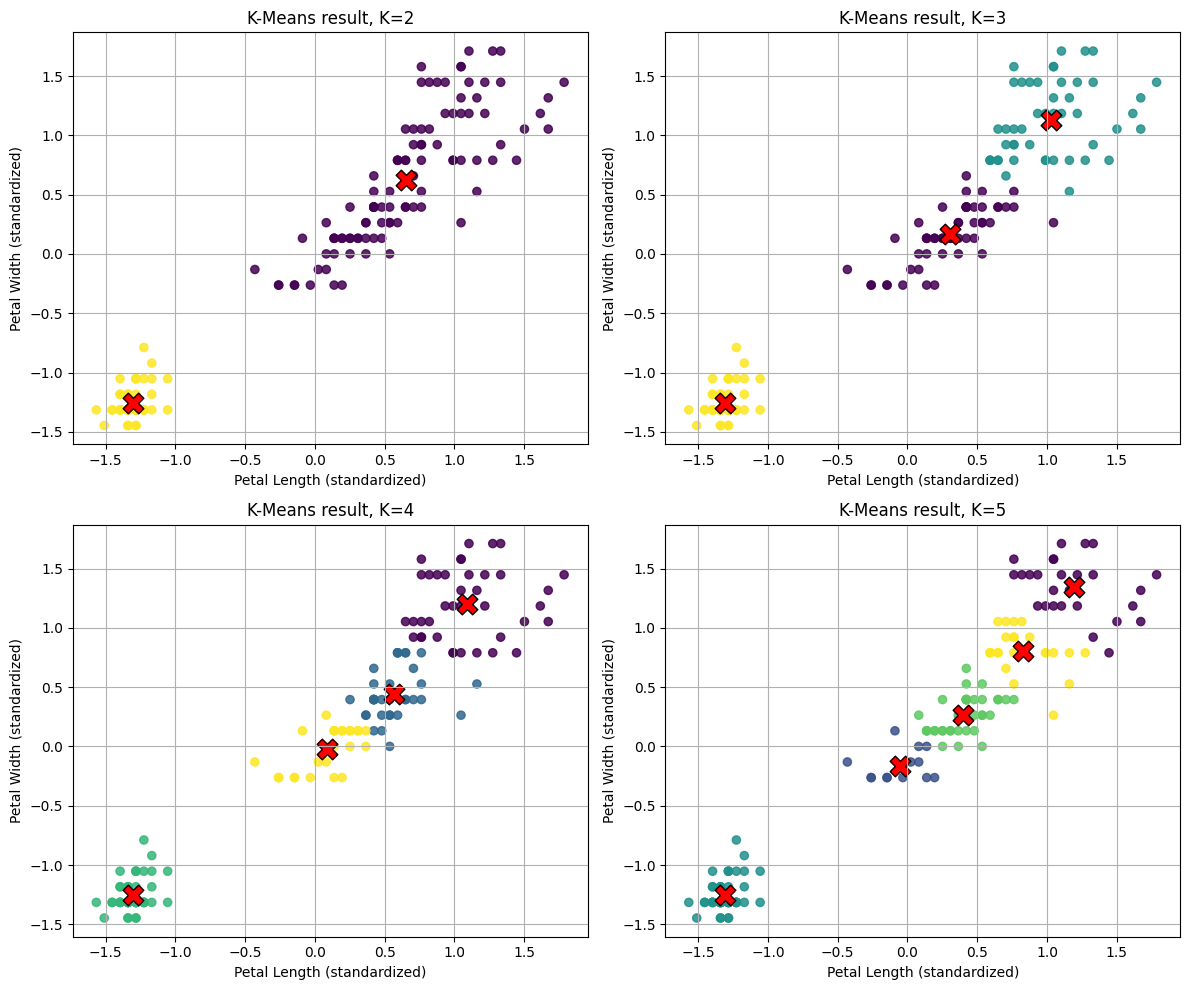

,K,Inertia,Iterations
0,2,54.1688,2
1,3,18.0270,5
2,4,12.5318,5
3,5,9.2273,7


In [3]:

iris = load_iris()
X_iris_original = iris.data[:, [2, 3]]
feature_labels = ["Petal Length", "Petal Width"]

iris_mean = X_iris_original.mean(axis=0)
iris_std = X_iris_original.std(axis=0)
X_iris = (X_iris_original - iris_mean) / iris_std


def euclidean_distances_to_centers(X, centers):
    distances = np.zeros((X.shape[0], centers.shape[0]))
    for center_index, center in enumerate(centers):
        distances[:, center_index] = np.sqrt(np.sum((X - center) ** 2, axis=1))
    return distances


def custom_kmeans(X, k, max_iter=100, tol=1e-5, random_state=42):
    rng = np.random.default_rng(random_state)
    initial_indices = rng.choice(X.shape[0], size=k, replace=False)
    centers = X[initial_indices].copy()

    for iteration in range(max_iter):
        distances = euclidean_distances_to_centers(X, centers)
        labels = np.argmin(distances, axis=1)

        new_centers = centers.copy()
        for cluster_id in range(k):
            cluster_points = X[labels == cluster_id]
            if len(cluster_points) > 0:
                new_centers[cluster_id] = cluster_points.mean(axis=0)
            else:
                new_centers[cluster_id] = X[rng.integers(0, X.shape[0])]

        center_shift = np.sqrt(np.sum((new_centers - centers) ** 2))
        centers = new_centers

        if center_shift < tol:
            break

    final_distances = euclidean_distances_to_centers(X, centers)
    labels = np.argmin(final_distances, axis=1)
    inertia = float(np.sum((X - centers[labels]) ** 2))

    return labels, centers, inertia, iteration + 1


k_list = [2, 3, 4, 5]
kmeans_results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, k in zip(axes, k_list):
    labels, centers, inertia, n_iter = custom_kmeans(X_iris, k=k, random_state=24)

    kmeans_results.append({
        "K": k,
        "Inertia": round(inertia, 4),
        "Iterations": n_iter
    })

    ax.scatter(X_iris[:, 0], X_iris[:, 1], c=labels, cmap="viridis", s=35, alpha=0.85)
    ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=220, edgecolors="black")
    ax.set_title(f"K-Means result, K={k}")
    ax.set_xlabel("Petal Length (standardized)")
    ax.set_ylabel("Petal Width (standardized)")
    ax.grid(True)

plt.tight_layout()
plt.show()

kmeans_result_df = pd.DataFrame(kmeans_results)
display(kmeans_result_df)



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
نمودارها نشان میدن که با تغییر مقدار <span dir="ltr">k</span>، تعداد خوشه‌ها و شکل تقسیم‌بندی داده‌ها تغییر می‌کنه. وقتی <span dir="ltr">k=2</span> انتخاب میشه، چند نوع گل در یک خوشه ادغام میشن و مدل خیلی ساده میشه. مقدار <span dir="ltr">k=3</span> برای دیتاست <span dir="ltr">Iris</span> منطقی‌تره، چون در این دیتاست سه نوع گل وجود داره.
</p>

<p>
وقتی مقدار <span dir="ltr">k</span> بزرگ‌تر مثل <span dir="ltr">4</span> یا <span dir="ltr">5</span> انتخاب میشه، بعضی گروه‌های طبیعی داده به چند قسمت کوچک‌تر شکسته میشن. مقدار <span dir="ltr">Inertia</span> معمولا با افزایش <span dir="ltr">k</span> کمتر میشه، چون هر خوشه نمونه‌های کمتری را پوشش میده، اما کمتر شدن <span dir="ltr">Inertia</span> همیشه به معنی بهتر شدن خوشه‌بندی از نظر مفهومی نیست.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۴. بررسی اثر مقداردهی اولیه مراکز</h3>

<p>
الگوریتم <span dir="ltr">K-Means</span> به مراکز اولیه حساسه. اگر مراکز اولیه خوب انتخاب نشن، الگوریتم ممکنه به یک جواب محلی ضعیف‌تر برسه. برای بررسی این موضوع، الگوریتم با مقدار ثابت <span dir="ltr">k=3</span> ولی با چند مقداردهی اولیه متفاوت اجرا شده و مقدار <span dir="ltr">Inertia</span> مقایسه میشه.
</p>

</div>


,Random State,Inertia,Iterations
0,3,18.027,7
1,12,18.027,3
2,24,18.027,5
3,41,18.027,8
4,88,18.027,5


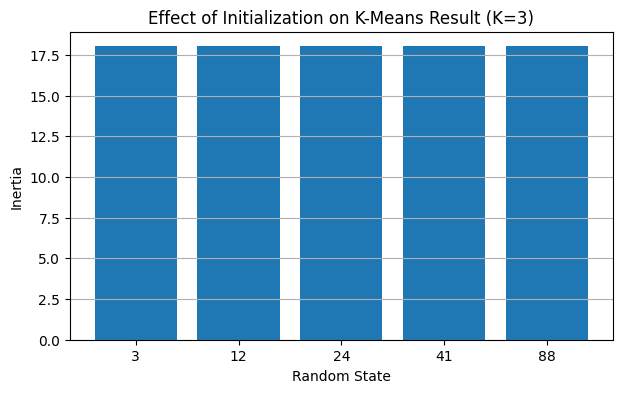

In [4]:

seed_values = [3, 12, 24, 41, 88]
initialization_rows = []

for seed in seed_values:
    labels, centers, inertia, n_iter = custom_kmeans(X_iris, k=3, random_state=seed)
    initialization_rows.append({
        "Random State": seed,
        "Inertia": round(inertia, 4),
        "Iterations": n_iter
    })

initialization_df = pd.DataFrame(initialization_rows)
display(initialization_df)

plt.figure(figsize=(7, 4))
plt.bar(initialization_df["Random State"].astype(str), initialization_df["Inertia"])
plt.xlabel("Random State")
plt.ylabel("Inertia")
plt.title("Effect of Initialization on K-Means Result (K=3)")
plt.grid(axis="y")
plt.show()



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
نتیجه بالا نشان میده مقداردهی اولیه می‌تونه روی جواب نهایی اثر داشته باشه. اگر مراکز اولیه متفاوت انتخاب بشن، مسیر حرکت مراکز در طول الگوریتم عوض میشه و ممکنه مقدار نهایی <span dir="ltr">Inertia</span> کمی فرق کنه.
</p>

<p>
برای کم کردن این مشکل، معمولا الگوریتم چند بار با مراکز اولیه متفاوت اجرا میشه و در نهایت حالتی انتخاب میشه که کمترین <span dir="ltr">Inertia</span> را داشته باشه. پس مقدار <span dir="ltr">k</span> و مقداردهی اولیه مراکز هر دو روی نتیجه نهایی خوشه‌بندی اثر دارن.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۵. جمع‌بندی</h3>

<p>
در بخش <span dir="ltr">PCA</span>، پیاده‌سازی دستی با خروجی کتابخانه مقایسه شد و نتیجه‌ها نزدیک بودن. سپس از <span dir="ltr">PCA</span> برای فشرده‌سازی تصویر استفاده شد و دیده شد که با افزایش مقدار <span dir="ltr">K</span> کیفیت بازسازی بهتر میشه ولی نرخ فشرده‌سازی کمتر میشه. همچنین مشخص شد که <span dir="ltr">PCA</span> برای آموزش مفهوم کاهش بعد مناسبه، اما در عمل معمولا جایگزین بهتری نسبت به <span dir="ltr">JPEG</span> برای فشرده‌سازی تصویر نیست.
</p>

<p>
در بخش <span dir="ltr">K-Means</span>، الگوریتم از پایه پیاده‌سازی شد و روی دو ویژگی گلبرگ دیتاست <span dir="ltr">Iris</span> اجرا شد. نتیجه‌ها نشان دادن مقدار <span dir="ltr">k</span> روی تعداد و شکل خوشه‌ها اثر مستقیم داره و مقداردهی اولیه مراکز هم می‌تونه جواب نهایی الگوریتم را تغییر بده.
</p>

</div>
